In [1]:
import pandas as pd
import numpy as np

In [2]:
#Read the csv files

chevalier_path = "../data/nestorowa_singlecell_raw_data_taken_from_bonesis_paper.tsv"
original_filtered_cells_path = "output/filtered_base.tsv"
conversion_table_path = "output/ensembl_to_symbol.tsv"

chevalier_df = pd.read_csv(chevalier_path, sep="\t", index_col=0)
original_filtered_cells_df = pd.read_csv(original_filtered_cells_path, sep="\t", index_col=0)
conversion_table_df = pd.read_csv(conversion_table_path, sep="\t", index_col=0)

# Create a dictionary for quick lookup
id_to_symbol = conversion_table_df['symbol'].to_dict()

In [3]:
#Compare the size of the df
print(f"Chevalier df shape: {chevalier_df.shape}")
print(f"Original filtered cells df shape: {original_filtered_cells_df.shape}")

Chevalier df shape: (4768, 1656)
Original filtered cells df shape: (43152, 1691)


In [4]:
original_filtered_cells_df = pd.read_csv(original_filtered_cells_path, sep="\t", index_col=0)

In [5]:
#Add the name column of the genes in second place to the filtered df by using the conversion table ensembl_to_symbol
df_names = conversion_table_df.join(original_filtered_cells_df, how='right')
df_names.index.name = "gene_id"

df_names.head(5)


,symbol,HSPC_025,HSPC_031,HSPC_037,LT-HSC_001,HSPC_001,HSPC_008,HSPC_014,HSPC_020,HSPC_026,...,Prog_851,Prog_809,Prog_816,Prog_822,Prog_828,Prog_834,Prog_840,Prog_846,Prog_852,Prog_810
gene_id,,,,,,,,,,,,,,,,,,,,,
ENSMUSG00000000001,Gnai3,185.0,2.0,2.0,136.0,232.0,354.0,181.0,318.0,4.0,...,43.0,1652.0,182.0,500.0,516.0,137.0,267.0,317.0,85.0,676.0
ENSMUSG00000000003,Pbsn,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ENSMUSG00000000028,Cdc45,4.0,3.0,1.0,1.0,2.0,2.0,0.0,122.0,103.0,...,5.0,4.0,50.0,401.0,293.0,5.0,596.0,649.0,102.0,457.0
ENSMUSG00000000031,H19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ENSMUSG00000000037,Scml2,0.0,0.0,0.0,0.0,0.0,1.0,20.0,0.0,59.0,...,3.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,134.0


### Normalization of the matrix

In [ ]:
R

library(Seurat)

# Remplace NormalizeData + FindVariableFeatures + ScaleData
seurat_obj <- SCTransform(seurat_obj, vars.to.regress = "percent.mt", verbose = FALSE)

# La suite du pipeline reste identique mais utilise l'assay "SCT"
seurat_obj <- RunPCA(seurat_obj, assay = "SCT")
seurat_obj <- RunUMAP(seurat_obj, dims = 1:30)

### 1. Suppressing genes that have very low expression 

Suppress genes that have null counts in almost all cells.

In [6]:
df_filtered = original_filtered_cells_df.copy()

Text(0, 0.5, 'Frequency')

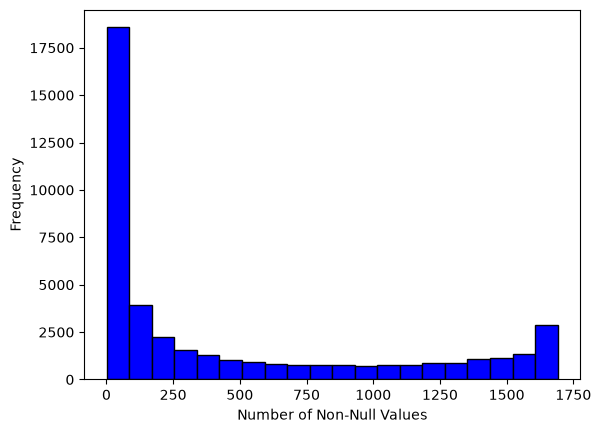

In [12]:
#Create a df counting the number of non null values for each row (gene) in the filtered df
non_null_counts =  (df_filtered != 0.0).sum(axis=1)


#plot a histogram of the non null counts
import matplotlib.pyplot as plt
non_null_counts.plot(kind="hist", bins=20, edgecolor="black", color="blue")
plt.xlabel("Number of Non-Null Values")
plt.ylabel("Frequency")


In [ ]:
# 2. Extraire et afficher les résultats pour 0, 1, 2 et 3 valeurs non-nulles
for k in [0, 1, 2,10,80,160,250,320,845]:
    subset_index = df_filtered.index[non_null_counts <= k].tolist()
    count = len(subset_index)

    print(f"=== Lignes avec au moins {k} valeurs non-nulles ===")
    print(f"Nombre de personnes/cellules : {count}")
    print(f"Liste des identifiants/index : {subset_index}\n")

=== Lignes avec au moins 0 valeurs non-nulles ===
Nombre de personnes/cellules : 0
Liste des identifiants/index : []

=== Lignes avec au moins 1 valeurs non-nulles ===
Nombre de personnes/cellules : 1243
Liste des identifiants/index : ['ENSMUSG00000023247', 'ENSMUSG00000025488', 'ENSMUSG00000025652', 'ENSMUSG00000027338', 'ENSMUSG00000027518', 'ENSMUSG00000031143', 'ENSMUSG00000033501', 'ENSMUSG00000037910', 'ENSMUSG00000039775', 'ENSMUSG00000044292', 'ENSMUSG00000046438', 'ENSMUSG00000054142', 'ENSMUSG00000058499', 'ENSMUSG00000059042', 'ENSMUSG00000059205', 'ENSMUSG00000060311', 'ENSMUSG00000061845', 'ENSMUSG00000062226', 'ENSMUSG00000062844', 'ENSMUSG00000063206', 'ENSMUSG00000063823', 'ENSMUSG00000064044', 'ENSMUSG00000064213', 'ENSMUSG00000064417', 'ENSMUSG00000064446', 'ENSMUSG00000064463', 'ENSMUSG00000064467', 'ENSMUSG00000064496', 'ENSMUSG00000064507', 'ENSMUSG00000064510', 'ENSMUSG00000064529', 'ENSMUSG00000064543', 'ENSMUSG00000064577', 'ENSMUSG00000064585', 'ENSMUSG00000064